# Deep Network Development, 2026 Autumn - Week 7 Practice - **Solutions**

## Exercises

---

### Exercise 7.1: Predicting body mass and species

#### Problem Description

Continue with the [Palmer Penguins dataset](https://allisonhorst.github.io/palmerpenguins/).
Train a regression network to predict body mass and a three-class network to predict species.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

DATA_URL = (
    'https://raw.githubusercontent.com/allisonhorst/palmerpenguins/'
    '156daa4301838d9fdcc5b018b29b9149bf975552/inst/extdata/penguins.csv'
)
species_dict = {'Adelie': 0, 'Chinstrap': 1, 'Gentoo': 2}
sex_dict = {'female': 0, 'male': 1}
SPECIES_NAMES = np.array(['Adelie', 'Chinstrap', 'Gentoo'])
COLUMN_NAMES = np.array(['species', 'bill_length_mm', 'bill_depth_mm',
                         'flipper_length_mm', 'body_mass_g', 'sex'])

CATEGORY_CONVERTERS = {'species': species_dict.get, 'sex': sex_dict.get} # dictionary's get will return None if an unknown key is used (e.g. data is missing)
FEATURE_COLUMNS = [1, 2, 3, 5]
FEATURE_NAMES = COLUMN_NAMES[FEATURE_COLUMNS]


PyTorch: 2.14.1+cpu


#### Task 1: Loading with Pandas and converting to NumPy

Load `DATA_URL` into the DataFrame `dataset_df` using `pd.read_csv`.
Use `COLUMN_NAMES` for `usecols` and `CATEGORY_CONVERTERS` for `converters`.

Convert `dataset_df` to the NumPy array `dataset_arr` with `np.float32` dtype using `.to_numpy()`.


In [ ]:
# Reference solution

# Load the dataset, selecting the specified columns and converting categorical values to numerical ones
dataset_df = pd.read_csv(DATA_URL, usecols=COLUMN_NAMES, converters=CATEGORY_CONVERTERS)

# Convert the DataFrame to a float32 NumPy array, replacing None values with np.nan
dataset_arr = dataset_df.to_numpy(dtype=np.float32)

# Prints
print(dataset_df.head())
print('Shape:', dataset_df.shape)
print('Column dtypes:')
print(dataset_df.dtypes)
print('NumPy:', dataset_arr.shape, dataset_arr.dtype)

# Test cases
assert dataset_df.shape == (344, 6)
assert np.array_equal(dataset_df.columns.to_numpy(), COLUMN_NAMES)
assert dataset_df.isna().sum().sum() == 19
assert np.allclose(dataset_df.iloc[0].to_numpy(dtype=np.float32), [0, 39.1, 18.7, 181, 3750, 1])
assert dataset_arr.shape == (344, 6) and dataset_arr.dtype == np.float32
assert np.isnan(dataset_arr).sum() == 19
print('Task 1 passed!')


   species  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  sex
0        0            39.1           18.7              181.0       3750.0  1.0
1        0            39.5           17.4              186.0       3800.0  0.0
2        0            40.3           18.0              195.0       3250.0  0.0
3        0             NaN            NaN                NaN          NaN  NaN
4        0            36.7           19.3              193.0       3450.0  0.0
Shape: (344, 6)
Column dtypes:
species                int64
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                  float64
dtype: object
NumPy: (344, 6) float32
Task 1 passed!


#### Provided setup

Apply the supplied fixed ordering to `dataset_arr`.


In [ ]:
# Provided fixed mixed ordering
row_order = np.random.default_rng(7).permutation(len(dataset_arr))
dataset_arr = dataset_arr[row_order]

# OR:
# np.random.shuffle(arr) # modifies the original array

# OR:
# shuffled = np.random.permutation(arr) # returns new array, but not reproducible

print('Dataset:', dataset_arr.shape)
print('Input columns:', FEATURE_NAMES)
assert dataset_arr.shape == (344, 6)
assert np.isnan(dataset_arr).sum() == 19


Dataset: (344, 6)
Input columns: ['bill_length_mm' 'bill_depth_mm' 'flipper_length_mm' 'sex']


#### Task 2: Inputs, targets, and PyTorch tensors

Create `complete_row_mask`, selecting rows of `dataset_arr` with no NaNs.
Create `clean_dataset_arr` from these rows. Keep `dataset_arr` unchanged.

Create `inputs_arr` from `FEATURE_COLUMNS` of `clean_dataset_arr`, then create:

- `X_class` and `X_reg`: inputs, `torch.float32`, shape `(333, 4)`.
- `y_class`: species indices (column 0), `torch.long`, shape `(333,)`.
- `y_reg`: body masses in grams (column 4), `torch.float32`, shape `(333, 1)`.


In [ ]:
# Reference solution

# Create a mask to identify rows without any missing values (np.nan)
complete_row_mask = ~np.isnan(dataset_arr).any(axis=1)

# Remove rows containing missing values from the dataset
clean_dataset_arr = dataset_arr[complete_row_mask]

# Extract the selected feature columns to use as model inputs
inputs_arr = clean_dataset_arr[:, FEATURE_COLUMNS]

# Convert the input features to a float32 PyTorch tensor for classification
X_class = torch.tensor(inputs_arr, dtype=torch.float32)

# Convert species labels to a long integer tensor for classification
y_class = torch.tensor(clean_dataset_arr[:, 0], dtype=torch.long)

# Convert the input features to a float32 PyTorch tensor for regression
X_reg = torch.tensor(inputs_arr, dtype=torch.float32)

# Convert body mass values to a float32 tensor and  reshape to column vector to match the model's output shape (N, 1)
y_reg = torch.tensor(clean_dataset_arr[:, 4], dtype=torch.float32).reshape(-1, 1)

# Prints
print('Rows kept / removed:', len(clean_dataset_arr), len(dataset_arr) - len(clean_dataset_arr))
print('Classification:', X_class.shape, X_class.dtype, y_class.shape, y_class.dtype)
print('Regression:', X_reg.shape, X_reg.dtype, y_reg.shape, y_reg.dtype)

# Test cases
assert complete_row_mask.shape == (344,) and complete_row_mask.dtype == np.bool_
assert np.array_equal(complete_row_mask, ~np.isnan(dataset_arr).any(axis=1))
assert clean_dataset_arr.shape == (333, 6) and np.isfinite(clean_dataset_arr).all()
assert np.array_equal(clean_dataset_arr, dataset_arr[complete_row_mask])
assert inputs_arr.shape == (333, 4) and np.isfinite(inputs_arr).all()
assert np.isnan(dataset_arr).sum() == 19
assert X_class.shape == X_reg.shape == (333, 4)
assert y_class.shape == (333,) and y_reg.shape == (333, 1)
assert X_class.dtype == X_reg.dtype == y_reg.dtype == torch.float32
assert y_class.dtype == torch.long
assert torch.equal(X_reg, X_class)
assert torch.equal(y_class, torch.tensor(clean_dataset_arr[:, 0], dtype=torch.long))
assert np.allclose(y_reg.numpy().ravel(), clean_dataset_arr[:, 4])
print('Task 2 passed!')


Rows kept / removed: 333 11
Classification: torch.Size([333, 4]) torch.float32 torch.Size([333]) torch.int64
Regression: torch.Size([333, 4]) torch.float32 torch.Size([333, 1]) torch.float32
Task 2 passed!


#### Task 3: Train, validation, and test splits

Split each task's inputs and targets by slicing: **70% training, 15% validation, and the remaining 15% testing**.
For each dataset, calculate the training and validation counts with `int(fraction * number_of_rows)`;
assign all remaining rows to testing.

Create `X_reg_train`, `X_reg_val`, `X_reg_test` and the corresponding `y_reg_*` tensors.
Use the same naming pattern for classification: `X_class_*`, `y_class_*`.


In [ ]:
TRAIN_FRACTION = 0.70
VAL_FRACTION = 0.15

# Reference solution
reg_train_end = int(TRAIN_FRACTION * len(X_reg))
reg_val_end = reg_train_end + int(VAL_FRACTION * len(X_reg))
class_train_end = int(TRAIN_FRACTION * len(X_class))
class_val_end = class_train_end + int(VAL_FRACTION * len(X_class))

# Split the regression inputs into training, validation, and test sets
X_reg_train, X_reg_val, X_reg_test = X_reg[:reg_train_end], X_reg[reg_train_end:reg_val_end], X_reg[reg_val_end:]

# Split the regression targets into training, validation, and test sets
y_reg_train, y_reg_val, y_reg_test = y_reg[:reg_train_end], y_reg[reg_train_end:reg_val_end], y_reg[reg_val_end:]

# Split the classification inputs into training, validation, and test sets
X_class_train, X_class_val, X_class_test = X_class[:class_train_end], X_class[class_train_end:class_val_end], X_class[class_val_end:]

# Split the classification targets into training, validation, and test sets
y_class_train, y_class_val, y_class_test = y_class[:class_train_end], y_class[class_train_end:class_val_end], y_class[class_val_end:]

# Prints
print('Regression split sizes:', len(X_reg_train), len(X_reg_val), len(X_reg_test))
print('Classification split sizes:', len(X_class_train), len(X_class_val), len(X_class_test))
print('Classification label counts (train / val / test):')
for labels in [y_class_train, y_class_val, y_class_test]:
    print(torch.bincount(labels, minlength=3))

# Test cases
for X, y, X_splits, y_splits in [
    (X_reg, y_reg, [X_reg_train, X_reg_val, X_reg_test], [y_reg_train, y_reg_val, y_reg_test]),
    (X_class, y_class, [X_class_train, X_class_val, X_class_test], [y_class_train, y_class_val, y_class_test])
]:
    n_train = int(TRAIN_FRACTION * len(X))
    n_val = int(VAL_FRACTION * len(X))
    assert [len(part) for part in X_splits] == [n_train, n_val, len(X) - n_train - n_val]
    assert [len(part) for part in y_splits] == [len(part) for part in X_splits]
    assert torch.equal(torch.cat(X_splits), X)
    assert torch.equal(torch.cat(y_splits), y)
assert all(torch.all(torch.bincount(y, minlength=3) > 0)
           for y in [y_class_train, y_class_val, y_class_test])
print('Task 3 passed!')


Regression split sizes: 233 49 51
Classification split sizes: 233 49 51
Classification label counts (train / val / test):
tensor([97, 45, 91])
tensor([27,  9, 13])
tensor([22, 14, 15])
Task 3 passed!


#### Task 4: A regression network

Define `RegressionNetwork`, a subclass of `nn.Module`, with two linear layers:
`self.hidden` (4 inputs, 16 outputs) and `self.output` (16 inputs, 1 output).
In `forward(x)`, apply the hidden layer, ReLU, and then the output layer with no output activation.

Create `reg_model`, `reg_loss_fn` using `nn.MSELoss`, and `reg_optimizer` using Adam
with learning rate `0.01` and `reg_model.parameters()`.


In [ ]:
torch.manual_seed(7)

# Reference solution
class RegressionNetwork(nn.Module):
    def __init__(self):
        super().__init__()

        # Solution A
        self.hidden = nn.Linear(4, 16)
        self.output = nn.Linear(16, 1)

        # Solution B
        # self.network = nn.Sequential(
        #     nn.Linear(4, 16),
        #     nn.ReLU(),
        #     nn.Linear(16, 1)
        # )

    def forward(self, x):
        # Solution A
        x = torch.relu(self.hidden(x))
        return self.output(x)

        # Solution B
        # return self.network(x)

reg_model = RegressionNetwork()
reg_loss_fn = nn.MSELoss()
reg_optimizer = torch.optim.Adam(reg_model.parameters(), lr=0.01)

# Prints
print('Prediction shape:', reg_model(X_reg_train[:5]).shape)
print('Initial training MSE:', reg_loss_fn(reg_model(X_reg_train), y_reg_train).item())

# Test cases
assert isinstance(reg_model, nn.Module)
assert reg_model.hidden.in_features == 4 and reg_model.hidden.out_features == 16
assert reg_model.output.in_features == 16 and reg_model.output.out_features == 1
assert reg_model(X_reg_train[:5]).shape == (5, 1)
assert isinstance(reg_loss_fn, nn.MSELoss)
assert {id(p) for g in reg_optimizer.param_groups for p in g['params']} == {id(p) for p in reg_model.parameters()}
assert torch.isclose(reg_loss_fn(torch.tensor([[1.], [3.]]),
                               torch.tensor([[2.], [5.]])), torch.tensor(2.5))
print('Task 4 passed!')


Prediction shape: torch.Size([5, 1])
Initial training MSE: 18779112.0
Task 4 passed!


#### Task 5: Manual mini-batch regression training

Train for `REG_EPOCHS` epochs with manual batches of size `BATCH_SIZE`.

At each epoch, call `reg_model.train()`. For each training batch, reset gradients,
predict, calculate the loss, collect its detached value, call `backward()`, and update parameters.
Use `.mean()` on the collected batch losses and append the result to `reg_train_losses`.

Call `reg_model.eval()` and use `torch.no_grad()` to collect validation batch losses in the same way.
Append their mean to `reg_val_losses`. Print the training and validation losses only after every 10th epoch (10, 20, 30, ...).


Epoch #10, tr loss: 6364432.5000, val loss: 4797978.0000
Epoch #20, tr loss: 337983.2812, val loss: 349408.8125
Epoch #30, tr loss: 334593.4062, val loss: 337506.0625
Epoch #40, tr loss: 332862.4688, val loss: 336129.0625
Epoch #50, tr loss: 330885.0625, val loss: 334490.1875
Epoch #60, tr loss: 328683.0000, val loss: 332662.5938
Epoch #70, tr loss: 326274.1562, val loss: 330661.8125
Epoch #80, tr loss: 323672.2500, val loss: 328498.0938
Epoch #90, tr loss: 320888.1562, val loss: 326179.6250
Epoch #100, tr loss: 317930.3125, val loss: 323712.2500
Epoch #110, tr loss: 314805.6562, val loss: 321100.7500
Epoch #120, tr loss: 311519.2500, val loss: 318348.6562
Epoch #130, tr loss: 308075.3125, val loss: 315458.0000
Epoch #140, tr loss: 304476.6250, val loss: 312430.2188
Epoch #150, tr loss: 300725.0312, val loss: 309266.0000
Epoch #160, tr loss: 296821.6562, val loss: 305964.9375
Epoch #170, tr loss: 292766.6562, val loss: 302526.0625
Epoch #180, tr loss: 288559.6250, val loss: 298948.0625

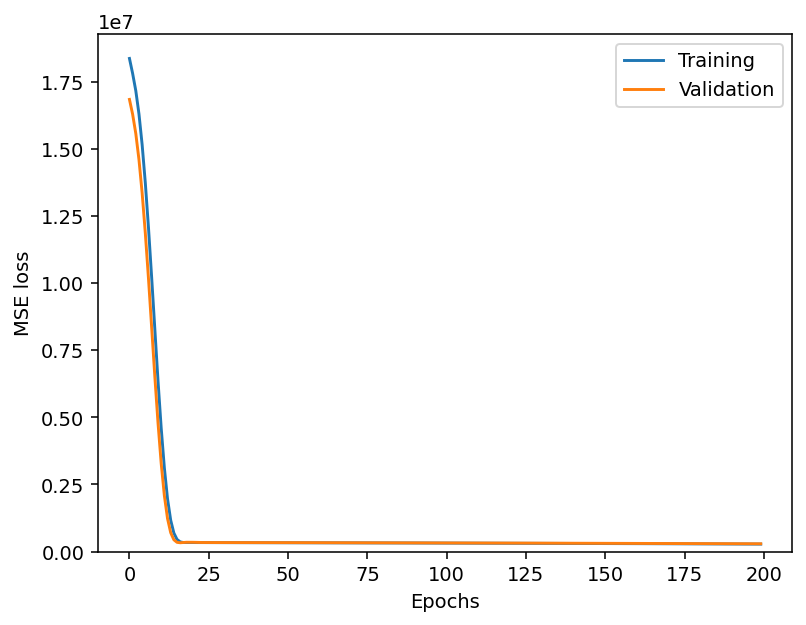

Task 5 passed!


In [ ]:
BATCH_SIZE = 32
REG_EPOCHS = 200
reg_train_losses, reg_val_losses = [], []
reg_initial_weights = reg_model.hidden.weight.detach().clone()

# Reference solution

# Go over the dataset REG_EPOCHS times
for epoch_idx in range(REG_EPOCHS):

    # Switch model to train mode
    reg_model.train()

    # Create list to collect train losses
    train_epoch_losses = []

    # Go over the train dataset in batches
    for start in range(0, len(X_reg_train), BATCH_SIZE):

        # Get the current batch of training inputs and targets
        x = X_reg_train[start:start + BATCH_SIZE]
        y = y_reg_train[start:start + BATCH_SIZE]

        # Reset gradients from the previous batch
        reg_optimizer.zero_grad()

        # Make predictions using the model
        y_hat = reg_model(x)

        # Calculate the loss between predictions and actual targets
        loss = reg_loss_fn(y_hat, y)

        # Store the loss without tracking gradients
        train_epoch_losses.append(loss.detach())

        # Compute gradients using backpropagation
        loss.backward()

        # Update model parameters using the optimizer
        reg_optimizer.step()

    # Calculate and store the average training loss for the epoch
    avg_tr_epoch_loss = torch.stack(train_epoch_losses).mean()
    reg_train_losses.append(avg_tr_epoch_loss.item())

    # Switch model to evaluation mode
    reg_model.eval()

    # Create list to collect validation losses
    val_epoch_losses = []

    # Disable gradient calculations during validation
    with torch.no_grad():

        # Go over the validation dataset in batches
        for start in range(0, len(X_reg_val), BATCH_SIZE):
            # Get the current batch of validation inputs and targets
            x = X_reg_val[start:start + BATCH_SIZE]
            y = y_reg_val[start:start + BATCH_SIZE]

            # Make predictions on the validation batch
            y_hat = reg_model(x)

            # Calculate and store the validation loss
            loss = reg_loss_fn(y_hat, y)
            val_epoch_losses.append(loss)

    # Calculate and store the average validation loss for the epoch
    avg_val_epoch_loss = torch.stack(val_epoch_losses).mean()
    reg_val_losses.append(avg_val_epoch_loss.item())

    
    if (epoch_idx + 1) % 10 == 0:
        print(f'Epoch #{epoch_idx + 1}, tr loss: {avg_tr_epoch_loss.item():.4f}, val loss: {avg_val_epoch_loss.item():.4f}')

# Prints
plt.plot(reg_train_losses, label='Training')
plt.plot(reg_val_losses, label='Validation')
plt.xlabel('Epochs')
plt.ylabel("MSE loss")
plt.ylim(bottom=0)
plt.legend()
plt.show()

# Test cases
assert len(reg_train_losses) == len(reg_val_losses) == REG_EPOCHS
assert np.isfinite(reg_train_losses).all() and np.isfinite(reg_val_losses).all()
assert min(reg_train_losses) >= 0 and min(reg_val_losses) >= 0
assert not torch.equal(reg_initial_weights, reg_model.hidden.weight.detach())
print('Task 5 passed!')


#### Task 6: Regression metrics and example predictions

Implement `mean_absolute_error(predictions, targets)` returning a scalar tensor:

$$\mathrm{MAE} = \frac{1}{N} \sum_{i=1}^{N} |\hat{y}_i - y_i|$$

Here, $N$ is the number of examples, $\hat{y}_i$ is a prediction, and $y_i$ is its target.
Calculate `reg_val_predictions` without gradients, then `reg_val_mae`.

Create `reg_example_predictions` from the first five validation predictions, as a 1D tensor in grams.


In [ ]:
# Reference solution

# Define a function to calculate the mean absolute error (MAE)
def mean_absolute_error(predictions, targets):
    return torch.abs(predictions - targets).mean()

# Disable gradient calculations during evaluation
with torch.no_grad():
    # Make predictions on the validation dataset
    reg_val_predictions = reg_model(X_reg_val)

# Calculate the mean absolute error on the validation dataset and get the first 5 predictions
reg_val_mae = mean_absolute_error(reg_val_predictions, y_reg_val)
reg_example_predictions = reg_val_predictions[:5, 0]

# Prints
print('Validation MAE (g):', reg_val_mae.item())
print('True / predicted validation mass (g):')
for true, predicted in zip(y_reg_val[:5, 0], reg_example_predictions):
    print(f'{true.item():.0f} / {predicted.item():.1f}')

# Test cases
assert torch.isclose(mean_absolute_error(torch.tensor([[1.], [4.]]),
                                        torch.tensor([[3.], [3.]])), torch.tensor(1.5))
assert reg_val_predictions.shape == y_reg_val.shape and not reg_val_predictions.requires_grad
assert reg_example_predictions.shape == (5,)
assert reg_val_mae.ndim == 0
assert torch.isfinite(reg_val_mae)
assert torch.allclose(reg_val_mae, (reg_val_predictions - y_reg_val).abs().mean())
print('Task 6 passed!')


Validation MAE (g): 433.13360595703125
True / predicted validation mass (g):
3450 / 3999.0
4300 / 4143.4
4800 / 4573.5
5850 / 5032.4
4300 / 3987.4
Task 6 passed!


#### Task 7: A multi-class network

Define `ClassificationNetwork`, a subclass of `nn.Module`, with `self.hidden` (4 inputs, 16 outputs)
and `self.output` (16 inputs, 3 outputs). In `forward(x)`, apply ReLU after the hidden layer
and no output activation. Return one raw score (logit) per species.

Create `class_model`, `class_loss_fn` using `nn.CrossEntropyLoss`, and `class_optimizer`
using Adam with learning rate `0.001` and `class_model.parameters()`.
Use integer class indices directly as targets.


In [9]:
torch.manual_seed(7)

# Reference solution
class ClassificationNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(4, 16)
        self.output = nn.Linear(16, 3)

    def forward(self, x):
        x = torch.relu(self.hidden(x))
        return self.output(x)

class_model = ClassificationNetwork()
class_loss_fn = nn.CrossEntropyLoss()
class_optimizer = torch.optim.Adam(class_model.parameters(), lr=0.001)

# Prints
print('Logit shape:', class_model(X_class_train[:5]).shape)
print('Target shape and dtype:', y_class_train[:5].shape, y_class_train.dtype)
print('Initial cross-entropy:', class_loss_fn(class_model(X_class_train), y_class_train).item())

# Test cases
assert isinstance(class_model, nn.Module)
assert class_model.hidden.in_features == 4 and class_model.hidden.out_features == 16
assert class_model.output.in_features == 16 and class_model.output.out_features == 3
assert class_model(X_class_train[:5]).shape == (5, 3)
assert isinstance(class_loss_fn, nn.CrossEntropyLoss)
assert {id(p) for g in class_optimizer.param_groups for p in g['params']} == {id(p) for p in class_model.parameters()}
assert torch.isclose(class_loss_fn(torch.zeros(2, 3), torch.tensor([0, 2])),
                     torch.tensor(np.log(3), dtype=torch.float32))
print('Task 7 passed!')


Logit shape: torch.Size([5, 3])
Target shape and dtype: torch.Size([5]) torch.int64
Initial cross-entropy: 20.66400146484375
Task 7 passed!


#### Task 8: Manual mini-batch classification training

Train for `CLASS_EPOCHS` epochs with manual batches of size `BATCH_SIZE`.

At each epoch, call `class_model.train()`. For each training batch, reset gradients,
predict, calculate the loss, collect its detached value, call `backward()`, and update parameters.
Use `.mean()` on the collected batch losses and append the result to `class_train_losses`.

Call `class_model.eval()` and use `torch.no_grad()` to collect validation batch losses in the same way.
Append their mean to `class_val_losses`. Print the training and validation losses only after every 10th epoch (10, 20, 30, ...).


Epoch #10, tr loss: 1.2372, val loss: 1.2285
Epoch #20, tr loss: 1.1472, val loss: 1.1330
Epoch #30, tr loss: 1.0657, val loss: 1.0481
Epoch #40, tr loss: 0.9836, val loss: 0.9644
Epoch #50, tr loss: 0.9046, val loss: 0.8851
Epoch #60, tr loss: 0.8302, val loss: 0.8115
Epoch #70, tr loss: 0.7606, val loss: 0.7437
Epoch #80, tr loss: 0.6958, val loss: 0.6815
Epoch #90, tr loss: 0.6352, val loss: 0.6240
Epoch #100, tr loss: 0.5787, val loss: 0.5708
Epoch #110, tr loss: 0.5261, val loss: 0.5216
Epoch #120, tr loss: 0.4774, val loss: 0.4762
Epoch #130, tr loss: 0.4325, val loss: 0.4344
Epoch #140, tr loss: 0.3916, val loss: 0.3963
Epoch #150, tr loss: 0.3545, val loss: 0.3618
Epoch #160, tr loss: 0.3213, val loss: 0.3309
Epoch #170, tr loss: 0.2916, val loss: 0.3034
Epoch #180, tr loss: 0.2653, val loss: 0.2790
Epoch #190, tr loss: 0.2420, val loss: 0.2575
Epoch #200, tr loss: 0.2215, val loss: 0.2386


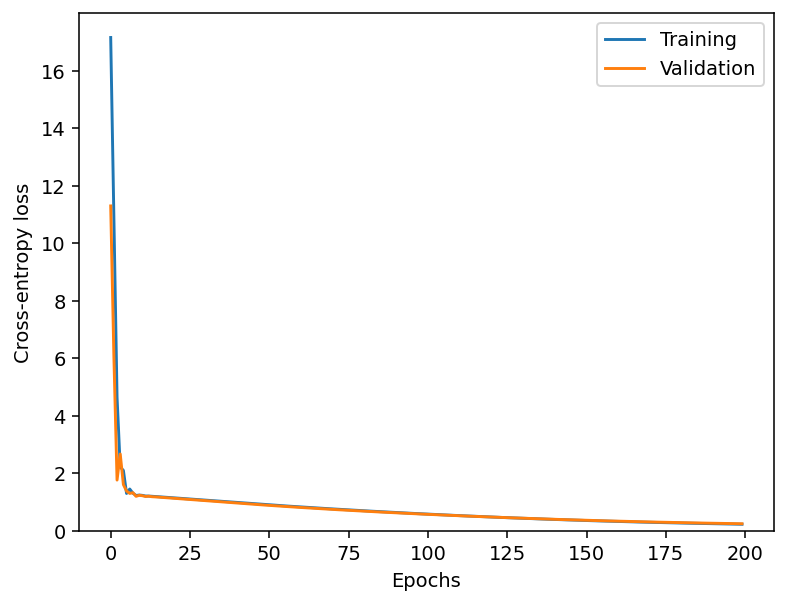

Task 8 passed!


In [ ]:
# Reuse BATCH_SIZE from Task 5
CLASS_EPOCHS = 200
class_train_losses, class_val_losses = [], []
class_initial_weights = class_model.hidden.weight.detach().clone()

# Reference solution

# Go over the dataset CLASS_EPOCHS times
for epoch_idx in range(CLASS_EPOCHS):

    # Switch model to train mode
    class_model.train()

    # Create list to collect training losses in each epoch
    train_epoch_losses = []

    # Go over the training dataset in batches
    for start in range(0, len(X_class_train), BATCH_SIZE):

        # Get the current batch of training inputs and targets
        x = X_class_train[start:start + BATCH_SIZE]
        y = y_class_train[start:start + BATCH_SIZE]

        # Reset gradients from the previous batch
        class_optimizer.zero_grad()

        # Make predictions using the classification model
        y_hat = class_model(x)

        # Calculate the loss between predictions and actual targets
        loss = class_loss_fn(y_hat, y)

        # Store the loss without tracking gradients
        train_epoch_losses.append(loss.detach())

        # Compute gradients using backpropagation
        loss.backward()

        # Update model parameters using the optimizer
        class_optimizer.step()

    # Calculate and store the average training loss for the epoch
    avg_tr_epoch_loss = torch.stack(train_epoch_losses).mean()
    class_train_losses.append(avg_tr_epoch_loss.item())

    # Switch model to evaluation mode
    class_model.eval()

    # Create list to collect validation losses
    val_epoch_losses = []

    # Disable gradient calculations during validation
    with torch.no_grad():

        # Go over the validation dataset in batches
        for start in range(0, len(X_class_val), BATCH_SIZE):

            # Get the current batch of validation inputs and targets
            x = X_class_val[start:start + BATCH_SIZE]
            y = y_class_val[start:start + BATCH_SIZE]

            # Make predictions on the validation batch
            y_hat = class_model(x)

            # Calculate and store the validation loss
            loss = class_loss_fn(y_hat, y)
            val_epoch_losses.append(loss)

    # Calculate and store the average validation loss for the epoch
    avg_val_epoch_loss = torch.stack(val_epoch_losses).mean()
    class_val_losses.append(avg_val_epoch_loss.item())

    
    if (epoch_idx + 1) % 10 == 0:
        print(f'Epoch #{epoch_idx + 1}, tr loss: {avg_tr_epoch_loss.item():.4f}, val loss: {avg_val_epoch_loss.item():.4f}')

# Prints
plt.plot(class_train_losses, label='Training')
plt.plot(class_val_losses, label='Validation')
plt.xlabel('Epochs')
plt.ylabel("Cross-entropy loss")
plt.ylim(bottom=0)
plt.legend()
plt.show()

# Test cases
assert len(class_train_losses) == len(class_val_losses) == CLASS_EPOCHS
assert np.isfinite(class_train_losses).all() and np.isfinite(class_val_losses).all()
assert min(class_train_losses) >= 0 and min(class_val_losses) >= 0
assert not torch.equal(class_initial_weights, class_model.hidden.weight.detach())
print('Task 8 passed!')


#### Task 9: Classification accuracy and predictions

Implement `classification_accuracy(logits, targets)`: select the largest score for each row
and return the proportion of correct predictions as a scalar tensor.

Calculate `class_test_logits` on the classification test split without gradients, then
`class_test_accuracy`. Create `class_example_predictions`: the predicted integer species
labels for the first five test examples.
Report accuracy on a 0-1 scale.


In [ ]:
# Reference solution

# Define a function to calculate classification accuracy
def classification_accuracy(logits, targets):
    # Get the predicted class for each sample by selecting the highest logit
    predictions = logits.argmax(dim=1)

    # Compare predictions with actual targets and return the mean accuracy
    return (predictions == targets).float().mean()

# Disable gradient calculations during evaluation
with torch.no_grad():
    # Make predictions on the test dataset
    class_test_logits = class_model(X_class_test)

# Calculate the classification accuracy on the test dataset
class_test_accuracy = classification_accuracy(class_test_logits, y_class_test)

# Get the predicted classes for the first 5 samples from the test dataset
class_example_predictions = class_test_logits[:5].argmax(dim=1)

# Prints
print('Test classification accuracy:', class_test_accuracy.item())
print('True / predicted test species:')
for true, predicted in zip(y_class_test[:5], class_example_predictions):
    print(SPECIES_NAMES[true.item()], '/', SPECIES_NAMES[predicted.item()])

# Test cases
toy_logits = torch.tensor([[4., 1., 0.], [0., 3., 1.], [2., 0., 4.], [1., 5., 2.]])
toy_targets = torch.tensor([0, 2, 2, 1])
assert torch.isclose(classification_accuracy(toy_logits, toy_targets), torch.tensor(0.75))
assert class_test_logits.shape == (len(X_class_test), 3) and not class_test_logits.requires_grad
assert class_example_predictions.shape == (5,) and class_example_predictions.dtype == torch.long
assert torch.equal(class_example_predictions, class_test_logits[:5].argmax(dim=1))
assert class_test_accuracy.ndim == 0 and 0 <= class_test_accuracy.item() <= 1
assert torch.allclose(class_test_accuracy,
                      (class_test_logits.argmax(dim=1) == y_class_test).float().mean())
print('Task 9 passed!')


Test classification accuracy: 0.9803921580314636
True / predicted test species:
Gentoo / Gentoo
Adelie / Adelie
Chinstrap / Chinstrap
Chinstrap / Chinstrap
Chinstrap / Chinstrap
Task 9 passed!


#### Quick recap: outputs, targets, and losses

For a batch of size `B`:

| Task | Output shape | Target shape / dtype | Loss | Prediction |
|---|---|---|---|---|
| Regression | `(B, 1)` | `(B, 1)` / `torch.float32` | `nn.MSELoss` | Scalar output directly |
| Binary classification | `(B, 1)`, after Sigmoid | `(B, 1)` / `torch.float32` | `nn.BCELoss` | Probability >= 0.5 predicts 1 |
| Multi-class classification (3 classes) | `(B, 3)` | `(B,)` / `torch.long` | `nn.CrossEntropyLoss` | `argmax(dim=1)` |


**Useful documentation links:**

- [MSELoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.MSELoss.html)
- [CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)
- [BCELoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCELoss.html)
